In [1]:
%load_ext autoreload
%autoreload 2

# DC4 Crab: time-integrated spectral analysis

Fit a point-source spectrum to the time-integrated, multienergy DC4 observation using the continuum detector response and the simulated background. This first analysis is phase-integrated and unpolarized; it does not separate the simulated nebula and pulsar components. The fitted model contains Crab and one free-normalization background component, so other sources and Galactic diffuse emission are not modeled explicitly. Interpret its results accordingly.


## Setup

Use the same configuration and paths as the Crab DataIO notebook. No time coordinate enters the likelihood.


In [2]:
from pathlib import Path
import sys

# Locate the workflow directory from the current notebook directory.
working_directory = Path.cwd().resolve()
candidates = [working_directory, *working_directory.parents]
workflow_dir = next(
    (directory for directory in candidates if (directory / "src" / "path_to_files.py").is_file()),
    None,
)
if workflow_dir is None and (working_directory / "workflow" / "src" / "path_to_files.py").is_file():
    workflow_dir = working_directory / "workflow"
if workflow_dir is None:
    raise FileNotFoundError("Start the notebook from the repository or workflow directory.")
if str(workflow_dir) not in sys.path:
    sys.path.insert(0, str(workflow_dir))

# Import the data, response, model, and fitting interfaces.
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.coordinates import SkyCoord
from astromodels import LinearPolarization, Model, PointSource, Powerlaw
from cosipy import BinnedData
from cosipy.background_estimation import FreeNormBinnedBackground
from cosipy.data_io import EmCDSBinnedData
from cosipy.interfaces import ThreeMLPluginInterface
from cosipy.response import BinnedInstrumentResponse, BinnedThreeMLModelFolding, BinnedThreeMLPointSourceResponse
from cosipy.response import FullDetectorResponse
from cosipy.spacecraftfile import SpacecraftHistory
from cosipy.statistics import PoissonLikelihood
from histpy import Histogram
from threeML import DataList, JointLikelihood
from src import path_to_files as paths

%matplotlib inline

In [3]:
# Import residual-analysis and plotting interfaces.
from src.residuals import ResidualAnalysis
from src.plot_residuals import PlottingResiduals
from IPython.display import display


## Load the observation

Add the 14 weekly sparse histograms with their common time axis intact, including any overlapping weekly boundary bins. Project over time only after addition; the projected histogram contains the ten measured-energy bins.


In [4]:
# Load and combine all weekly time-resolved observations.
observed_temporal = None
for week in sorted(paths.weekly_paths):
    weekly_path = paths.data_dir_out / f"dc4_week_{week}_crab_continuum_binned.hdf5"
    if not weekly_path.is_file():
        raise FileNotFoundError(f"Missing binned observation: {weekly_path}")
    weekly_data = BinnedData(paths.config_continuum_path)
    weekly_data.load_binned_data_from_hdf5(binned_data=str(weekly_path))
    weekly_histogram = weekly_data.binned_data
    if observed_temporal is None:
        observed_temporal = weekly_histogram.copy()
    else:
        if weekly_histogram.axes != observed_temporal.axes:
            raise ValueError(f"Week {week} has incompatible histogram axes.")
        observed_temporal = observed_temporal + weekly_histogram

# Sum the time axis while retaining the measured-energy and CDS axes.
observed_integrated = observed_temporal.project("Em", "Phi", "PsiChi").to_dense(copy=False)

In [5]:
print("Temporal axes:", observed_temporal.axes.labels)
print("Temporal shape:", observed_temporal.shape)
print("Integrated axes:", observed_integrated.axes.labels)
print("Integrated shape:", observed_integrated.shape)
print("Observed counts:", np.asarray(observed_integrated.contents).sum())

Temporal axes: ['Time' 'Em' 'Phi' 'PsiChi']
Temporal shape: (2217, 10, 30, 768)
Integrated axes: ['Em' 'Phi' 'PsiChi']
Integrated shape: (10, 30, 768)
Observed counts: 182327957.0


## Load the simulated background

Project the background over the same full time range. It is a provisional background template, not a Crab fit. The DC4 simulation may share background events with the observation; some events were reported outside the binning range and their number has not yet been established.


In [6]:
# Load the time-resolved simulated background created by DataIO.
background_path = paths.data_dir_out / "simulated_background_crab_continuum_binned.hdf5"
if not background_path.is_file():
    raise FileNotFoundError(f"Missing binned background: {background_path}")
background_temporal = Histogram.open(background_path)

# Check time and CDS axes before projecting the background.
if observed_temporal.axes != background_temporal.axes:
    raise ValueError("Observed and background temporal axes do not match.")
background_integrated = background_temporal.project("Em", "Phi", "PsiChi").to_dense(copy=True)
if observed_integrated.axes != background_integrated.axes:
    raise ValueError("Observed and background integrated axes do not match.")

# Check that both inputs contain finite, non-negative counts.
for name, histogram in (("Observation", observed_integrated), ("Background", background_integrated)):
    values = np.asarray(histogram.contents)
    if not np.all(np.isfinite(values)) or np.any(values < 0):
        raise ValueError(f"{name} contains invalid counts.")
    print(f"{name} total:", values.sum())
if np.asarray(background_integrated.contents).sum() <= 0:
    raise ValueError("The integrated background must have positive total counts.")

Observation total: 182327957.0
Background total: 168648542.0


## Inspect measured-energy counts

The background is shown at its simulation normalization. The fit below will determine its overall normalization.


In [7]:
# Compare the observed and simulated-background measured-energy distributions.
energy_edges = observed_integrated.axes["Em"].edges.to_value(u.keV)
observed_energy = np.asarray(observed_integrated.project("Em").contents)
background_energy = np.asarray(background_integrated.project("Em").contents)

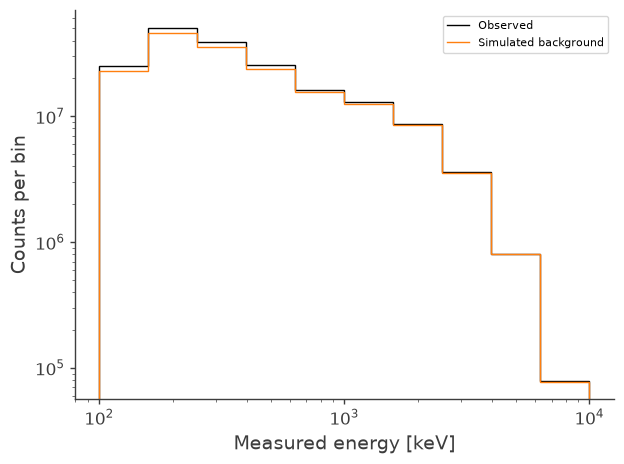

In [8]:


fig, ax = plt.subplots()
ax.stairs(observed_energy, energy_edges, label="Observed", color="black")
ax.stairs(background_energy, energy_edges, label="Simulated background", color="tab:orange")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set(xlabel="Measured energy [keV]", ylabel="Counts per bin")
ax.legend()
fig.tight_layout()
plt.show()

## Define the Crab model

Use a fixed Crab position and a single power law with free normalization and index. Coordinates and starting spectral parameters follow the installed COSIpy Crab response example; they are starting assumptions, not fitted DC4 results. Zero polarization is fixed for this first analysis.


In [9]:
# Set the fixed Crab coordinates from the COSIpy response example.
crab_position = SkyCoord(ra=83.6330 * u.deg, dec=22.0144 * u.deg, frame="icrs")

# Set initial spectral parameters; the likelihood will fit K and index.
crab_spectrum = Powerlaw()
crab_spectrum.K.unit = 1 / (u.keV * u.cm**2 * u.s)
crab_spectrum.K.value = 1e-3
crab_spectrum.K.free = True
crab_spectrum.piv.unit = u.keV
crab_spectrum.piv.value = 100.0
crab_spectrum.piv.free = False
crab_spectrum.index.value = -2.0
crab_spectrum.index.free = True

# Use one fixed, unpolarized point source for the phase-integrated fit.
crab_polarization = LinearPolarization(degree=0.0, angle=0.0)
crab_polarization.degree.free = False
crab_polarization.angle.free = False
crab_source = PointSource(
    "Crab",
    ra=crab_position.ra.deg,
    dec=crab_position.dec.deg,
    spectral_shape=crab_spectrum,
    polarization=crab_polarization,
)
crab_source.position.ra.free = False
crab_source.position.dec.free = False
crab_model = Model(crab_source)
crab_model.display(complete=True)

Model summary:
==============

                  N
Point sources     1
Extended sources  0
Particle sources  0

Free parameters (2):
--------------------

                                   value min_value max_value            unit
Crab.spectrum.main.Powerlaw.K      0.001       0.0    1000.0  keV-1 s-1 cm-2
Crab.spectrum.main.Powerlaw.index   -2.0     -10.0      10.0                

Fixed parameters (5):
---------------------

                                          value min_value max_value unit
Crab.position.ra                         83.633       0.0     360.0  deg
Crab.position.dec                       22.0144     -90.0      90.0  deg
Crab.spectrum.main.Powerlaw.piv           100.0      None      None  keV
Crab.spectrum.main.polarization.degree      0.0       0.0     100.0     
Crab.spectrum.main.polarization.angle       0.0       0.0     180.0  deg

Properties (0):
--------------------

(none)


Linked parameters (0):
----------------------

(none)

Independent variables:
----------------------

(none)

Linked functions (0):
----------------------

(none)

## Build the response and likelihood

COSIpy uses the spacecraft history to calculate a point-source response in the coordinate frame of the data. Check the response-folded expectation against the actual observed CDS axes before fitting. This calculation can take time.


In [10]:
# Wrap the observed CDS and open the observing history and continuum response.
crab_data = EmCDSBinnedData(observed_integrated)
spacecraft_history = SpacecraftHistory.open(paths.data_ori_path)
detector_response = FullDetectorResponse.open(paths.data_responsecon_path)
instrument_response = BinnedInstrumentResponse(detector_response, crab_data)

# Build the point-source response for the observed Galactic CDS frame.
point_response = BinnedThreeMLPointSourceResponse(
    data=crab_data,
    instrument_response=instrument_response,
    sc_history=spacecraft_history,
    energy_axis=detector_response.axes["Ei"],
    nside=2 * crab_data.axes["PsiChi"].nside,
)
model_folding = BinnedThreeMLModelFolding(
    data=crab_data,
    point_source_response=point_response,
)
model_folding.set_model(crab_model)

# Fold the initial spectrum to verify the actual predicted axes.
initial_source_expectation = model_folding.expectation(copy=True)
if initial_source_expectation.axes != observed_integrated.axes:
    raise ValueError("Folded source and observed CDS axes do not match.")
if initial_source_expectation.shape != observed_integrated.shape:
    raise ValueError("Folded source and observed CDS shapes do not match.")

In [11]:

print("Folded source axes:", initial_source_expectation.axes.labels)
print("Folded source PsiChi frame:", initial_source_expectation.axes["PsiChi"].coordsys)
print("Observed PsiChi frame:", observed_integrated.axes["PsiChi"].coordsys)
print("Initial source prediction and data axes match:", initial_source_expectation.axes == observed_integrated.axes)

Folded source axes: ['Em' 'Phi' 'PsiChi']
Folded source PsiChi frame: <Galactic Frame>
Observed PsiChi frame: <Galactic Frame>
Initial source prediction and data axes match: True


The simulated background provides one common shape with one fitted normalization across all measured-energy bins. A negligible floor is added before normalization, following the existing 511 keV fit workflow.


In [12]:
# Copy the template because FreeNormBinnedBackground normalizes it in place.
background_distribution = {"background": background_integrated.copy()}
background_distribution["background"] += sys.float_info.min
background_model = FreeNormBinnedBackground(
    background_distribution,
    sc_history=spacecraft_history,
    copy=False,
)

# Initialize the background rate from the simulation and the observing livetime.
background_rate = (
    float(np.asarray(background_integrated.contents).sum())
    / spacecraft_history.cumulative_livetime()
).to(u.Hz)
background_model.set_norm({"background": background_rate})
if background_model.axes != crab_data.axes:
    raise ValueError("Background model and observed CDS axes do not match.")

# Connect the source and background expectations to the integrated likelihood.
poisson_likelihood = PoissonLikelihood(data=crab_data, response=model_folding, bkg=background_model)
cosi_plugin = ThreeMLPluginInterface(
    name="cosi_crab", likelihood=poisson_likelihood, response=model_folding, bkg=background_model,
)
cosi_plugin.bkg_parameter["background"].min_value = 0.0
crab_likelihood = JointLikelihood(crab_model, DataList(cosi_plugin), verbose=False)
print("Initial background rate:", background_model.norm)

Initial background rate: 25.632210992992686 Hz


## Fit the integrated model

The optimizer estimates the power-law parameters and the background normalization from the observed CDS counts. Inspect fit convergence and warnings before interpreting or saving results.


In [13]:
# Fit the time-integrated observation and display the optimizer results.
crab_likelihood.fit()
crab_fit_results = crab_likelihood.results
crab_fit_results.display()

Best fit values:

,result,unit
parameter,,
Crab.spectrum.main.Powerlaw.K,(8.30 +/- 0.04) x 10^-4,1 / (keV s cm2)
Crab.spectrum.main.Powerlaw.index,-2.794 +/- 0.005,
background,(2.71220 +/- 0.00028) x 10,Hz


Correlation matrix:

1.00,-0.72,-0.27
-0.72,1.00,-0.24
-0.27,-0.24,1.00


Values of -log(likelihood) at the minimum:

,-log(likelihood)
cosi_crab,-1172950351.7431698
total,-1172950351.7431698


... (6 outputs left out)

Values of -log(likelihood) at the minimum:

,-log(likelihood)
cosi_crab,-1172950351.7431698
total,-1172950351.7431698


Values of statistical measures:

,statistical measures
AIC,-2345900697.4862356
BIC,-2345900666.443623


## Evaluate the fitted expectation

Evaluate the fitted source and background in the same measured-energy and CDS bins as the observation. These are real fit products only after the fit above completes successfully.


In [14]:
# Evaluate the fitted source and background contributions.
source_expectation = model_folding.expectation(copy=True)
background_expectation = background_model.expectation(copy=True)
total_expectation = source_expectation + background_expectation

# Check all fitted components before using or saving them.
for name, histogram in (
    ("Source", source_expectation),
    ("Background", background_expectation),
    ("Total", total_expectation),
):
    if histogram.axes != observed_integrated.axes or histogram.shape != observed_integrated.shape:
        raise ValueError(f"{name} expectation does not match the observed CDS.")
    values = np.asarray(histogram.contents)
    if not np.all(np.isfinite(values)) or np.any(values < 0):
        raise ValueError(f"{name} expectation contains invalid counts.")
    print(f"{name} expectation:", values.sum())
print("Observed counts:", np.asarray(observed_integrated.contents).sum())

Source expectation: 3876940.6615251154
Background expectation: 178451015.85071227
Total expectation: 182327956.51223737
Observed counts: 182327957.0


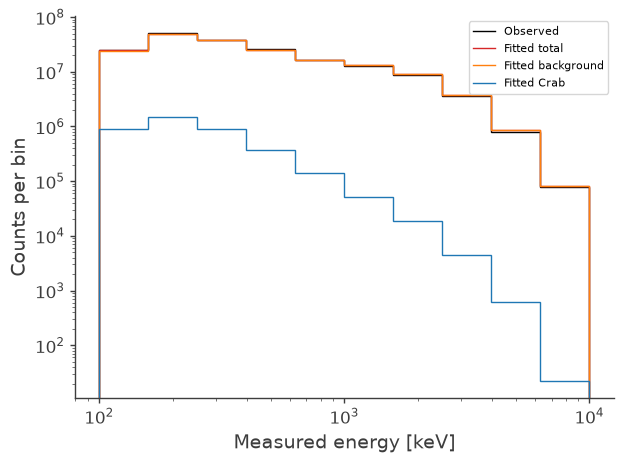

In [15]:
# Compare the fitted expectation and its components in measured energy.
source_energy = np.asarray(source_expectation.project("Em").contents)
fitted_background_energy = np.asarray(background_expectation.project("Em").contents)
total_energy = np.asarray(total_expectation.project("Em").contents)

fig, ax = plt.subplots()
ax.stairs(observed_energy, energy_edges, label="Observed", color="black")
ax.stairs(total_energy, energy_edges, label="Fitted total", color="tab:red")
ax.stairs(fitted_background_energy, energy_edges, label="Fitted background", color="tab:orange")
ax.stairs(source_energy, energy_edges, label="Fitted Crab", color="tab:blue")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set(xlabel="Measured energy [keV]", ylabel="Counts per bin")
ax.legend()
fig.tight_layout()
plt.show()

## Integrated multienergy residuals

Compare the observed counts with the fitted Crab plus background expectation. The residuals use projected counts: `raw` is D − M, `pearson` is (D − M)/√M, and `fractional` is (D − M)/M. Normalized residuals require positive expected counts. Shared simulated background and omitted sky components affect interpretation; nominal Poisson or Gaussian references are not calibrated goodness-of-fit tests.


### Explortation of fit results

In [61]:
# Identify bins rejected by the residual-analysis numerical threshold.
numerical_floor = 10 * np.finfo(float).tiny
floor_bins = np.asarray(total_expectation.contents) <= numerical_floor

# Inspect how many affected bins contain observed events.
affected_observed = np.asarray(observed_integrated.contents)[floor_bins]

print("Numerical threshold:", numerical_floor)
print("Bins at or below threshold:", np.count_nonzero(floor_bins))
print("Affected bins with observed counts:", np.count_nonzero(affected_observed))
print("Observed counts in affected bins:", affected_observed.sum())

Numerical threshold: 2.2250738585072014e-307
Bins at or below threshold: 9302
Affected bins with observed counts: 2
Observed counts in affected bins: 2.0


In [62]:
# Locate floor-level bins that contain observed events.
affected_bins = floor_bins & (np.asarray(observed_integrated.contents) > 0)

# Report the observed and fitted component counts in each affected bin.
for index in np.argwhere(affected_bins):
    energy_index, phi_index, psichi_index = map(int, index)
    bin_index = (energy_index, phi_index, psichi_index)

    print("CDS bin indices:", bin_index)
    print("Measured-energy interval [keV]:", energy_edges[energy_index:energy_index + 2])
    print("Observed:", observed_integrated.contents[bin_index])
    print("Fitted source:", source_expectation.contents[bin_index])
    print("Fitted background:", background_expectation.contents[bin_index])
    print("Total expectation:", total_expectation.contents[bin_index])
    print()

CDS bin indices: (1, 3, 44)
Measured-energy interval [keV]: [158.489 251.189]
Observed: 1.0
Fitted source: 0.0
Fitted background: 2.354403326388686e-308
Total expectation: 2.354403326388686e-308

CDS bin indices: (1, 3, 216)
Measured-energy interval [keV]: [158.489 251.189]
Observed: 1.0
Fitted source: 0.0
Fitted background: 2.354403326388686e-308
Total expectation: 2.354403326388686e-308



In [63]:
# Inspect the original simulated-background counts in the affected bins.
for index in np.argwhere(affected_bins):
    bin_index = tuple(map(int, index))
    print(
        "CDS bin:", bin_index,
        "| Original simulated background:", background_integrated.contents[bin_index],
    )

CDS bin: (1, 3, 44) | Original simulated background: 0.0
CDS bin: (1, 3, 216) | Original simulated background: 0.0


### Residual initialization

In [64]:
# Prepare residuals from the in-memory observation and fitted expectation.
crab_residuals = ResidualAnalysis(
    observed=observed_integrated,
    expected=total_expectation,
)
crab_plotter = PlottingResiduals(crab_residuals)

# Inspect the energy bins, total counts, and valid-bin mask.
display(crab_residuals.data_summary_table())


Observed data have no time information; using atemporal residual analysis.


,Statistic,Value
0,Em bins,10
1,Em edges [keV],"(100.0, 158.489, 251.189, 398.107, 630.957, 10..."
2,Phi bins,30
3,Phi range [deg],"(0.0, 180.0)"
4,PsiChi bins,768
5,PsiChi HEALPix nside,8
6,Total bins,230400
7,Valid bins,221100
8,Excluded bins,9300
9,Occupied floor bins retained,2


### Residuals versus measured energy

`Em_projection` sums the angular coordinates and preserves each measured-energy bin. The examples show raw and fractional residuals; `residual_type="pearson"` is also available. The fractional residual is undefined where the projected expectation is zero.


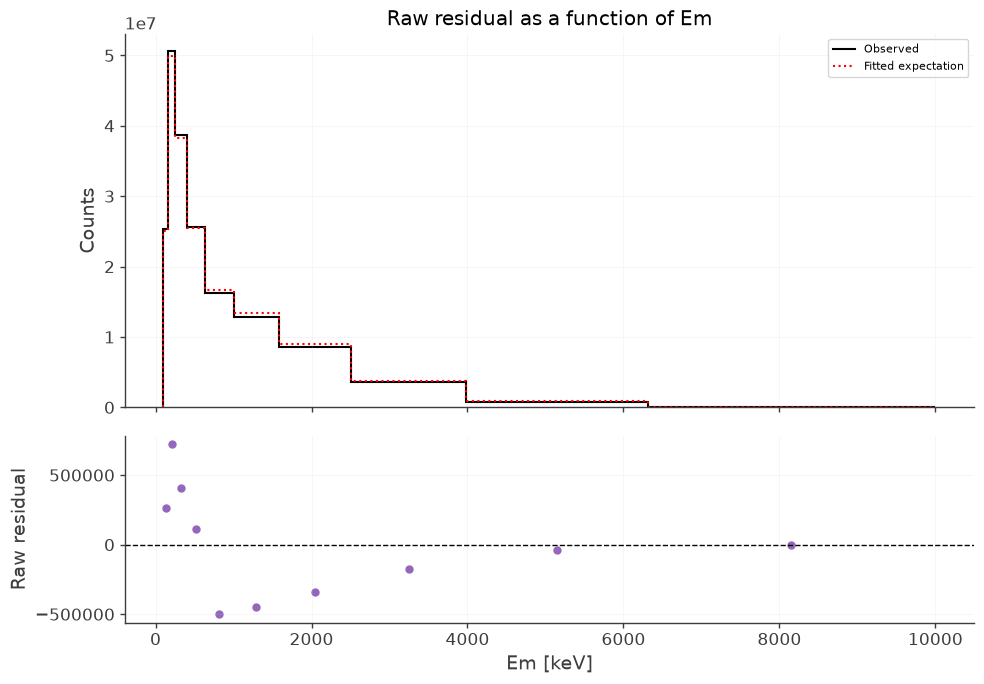

In [65]:
# Compare observed and fitted counts and their difference per energy bin.
crab_energy_raw_figure = crab_plotter.plot(
    "Em_projection",
    residual_type="raw",
    show_uncertainty=False,
)


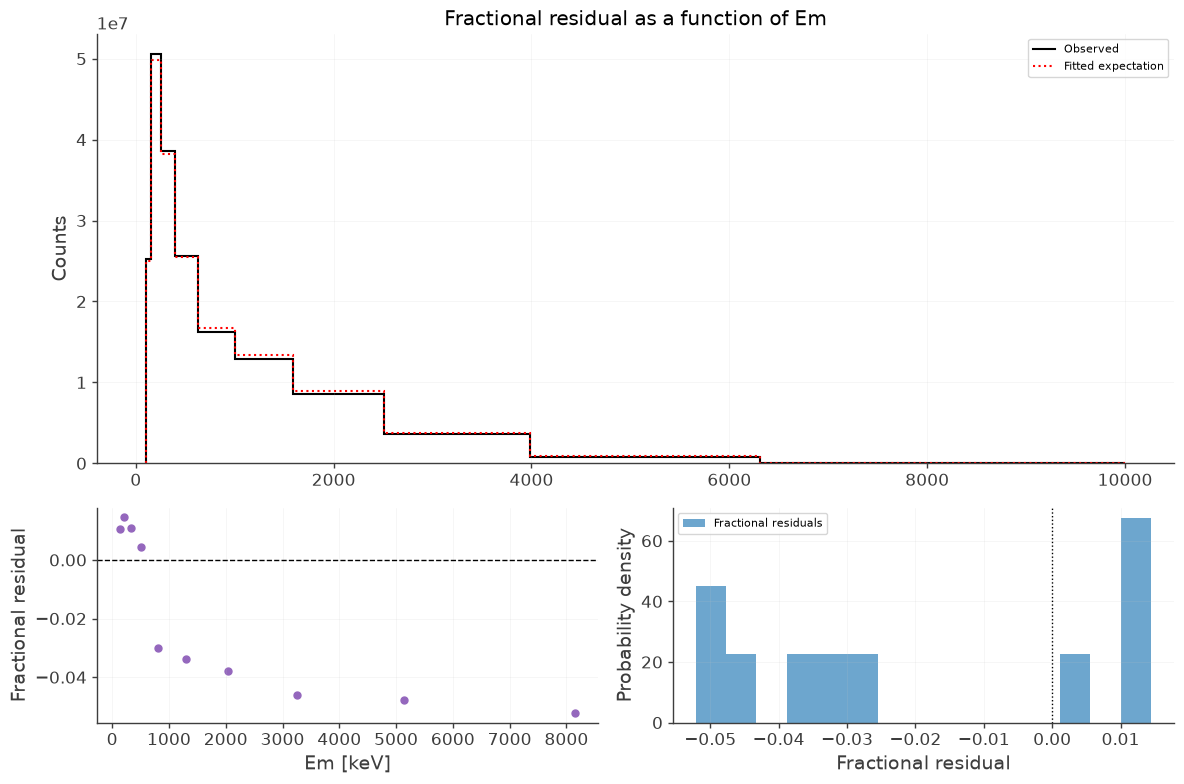

In [66]:
# Show the relative difference between observation and expectation.
crab_energy_fractional_figure = crab_plotter.plot(
    "Em_projection",
    residual_type="fractional",
    show_uncertainty=False,
)


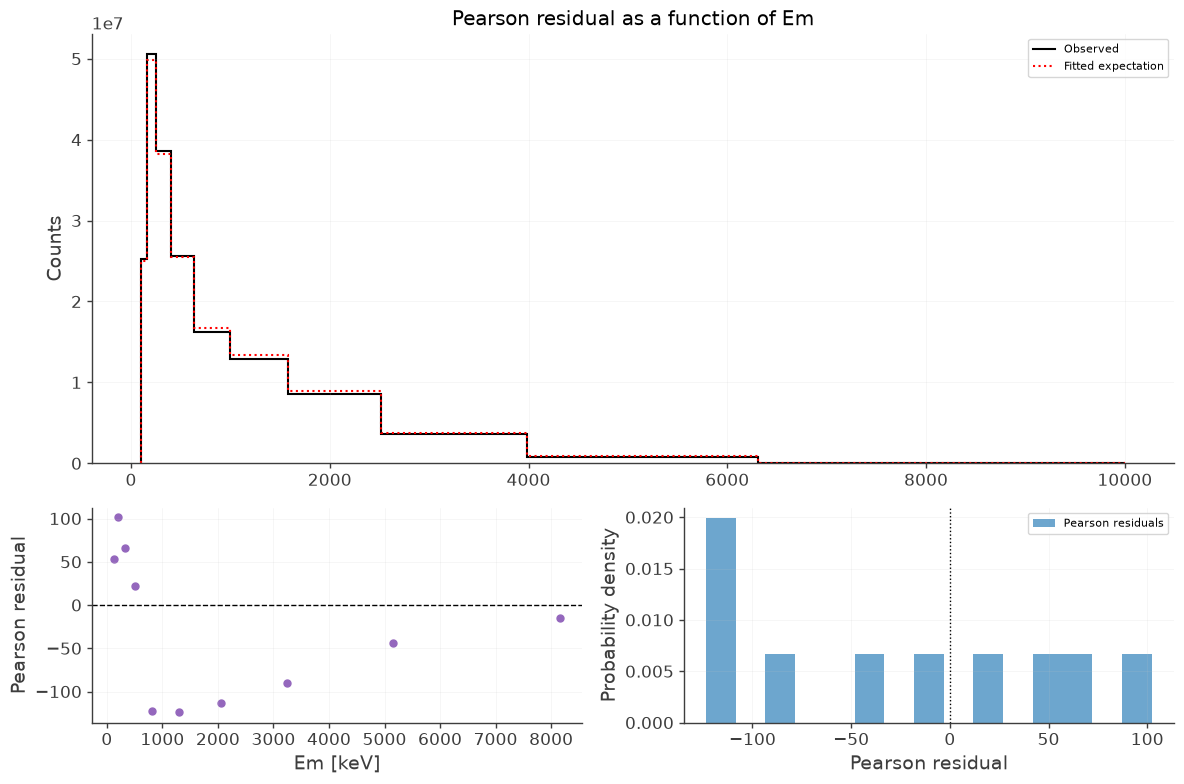

In [67]:
# Show the relative difference between observation and expectation.
crab_energy_fractional_figure = crab_plotter.plot(
    "Em_projection",
    residual_type="pearson",
    show_uncertainty=False,
    show_gaussian_reference=False
)

### Angular map for one energy bin

`Em_PsiChi_projection` selects a measured-energy bin by its zero-based index. Change `energy_bin_index` to inspect another bin without repeating the fit. Here `pearson` scales the count difference by the square root of the expectation.


Selected measured-energy interval [keV]: [398.107 630.957]


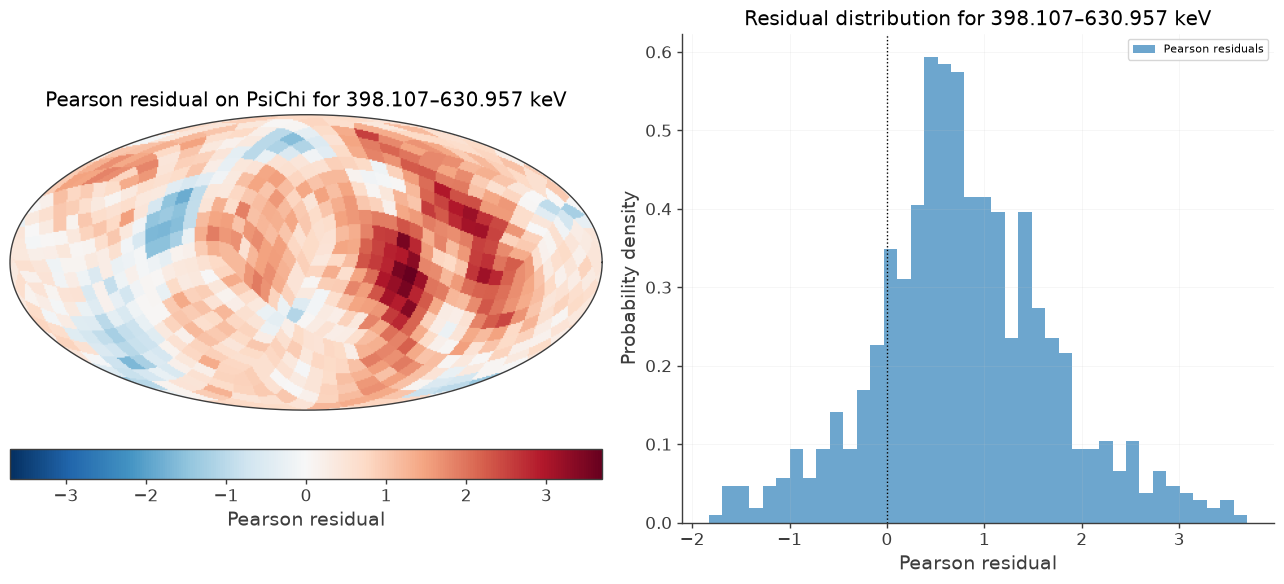

In [68]:
# Select one measured-energy bin for the PsiChi map.
energy_bin_index = 3
print("Selected measured-energy interval [keV]:", energy_edges[energy_bin_index:energy_bin_index + 2])
crab_energy_psichi_figure = crab_plotter.plot(
    "Em_PsiChi_projection",
    residual_type="pearson",
    energy_bin_index=energy_bin_index,
    show_gaussian_reference=False,
)


### Angular residuals in an energy interval

Select an interval using existing measured-energy edges. The selected bins are combined before projecting the counts. Adjacent edges select one bin; choosing more widely separated edges combines several bins.


In [69]:
# Select the same measured-energy bin by its physical edges in keV.
energy_min = float(energy_edges[energy_bin_index])
energy_max = float(energy_edges[energy_bin_index + 1])
crab_selected_residuals = crab_residuals.select_energy_range(energy_min, energy_max)
crab_selected_plotter = PlottingResiduals(crab_selected_residuals)
print(f"Selected interval: {energy_min:g}–{energy_max:g} keV")
display(crab_selected_residuals.data_summary_table())


Observed data have no time information; using atemporal residual analysis.
Selected interval: 398.107–630.957 keV


,Statistic,Value
0,Em bins,1
1,Em edges [keV],"(398.107, 630.957)"
2,Phi bins,30
3,Phi range [deg],"(0.0, 180.0)"
4,PsiChi bins,768
5,PsiChi HEALPix nside,8
6,Total bins,23040
7,Valid bins,22272
8,Excluded bins,768
9,Occupied floor bins retained,0


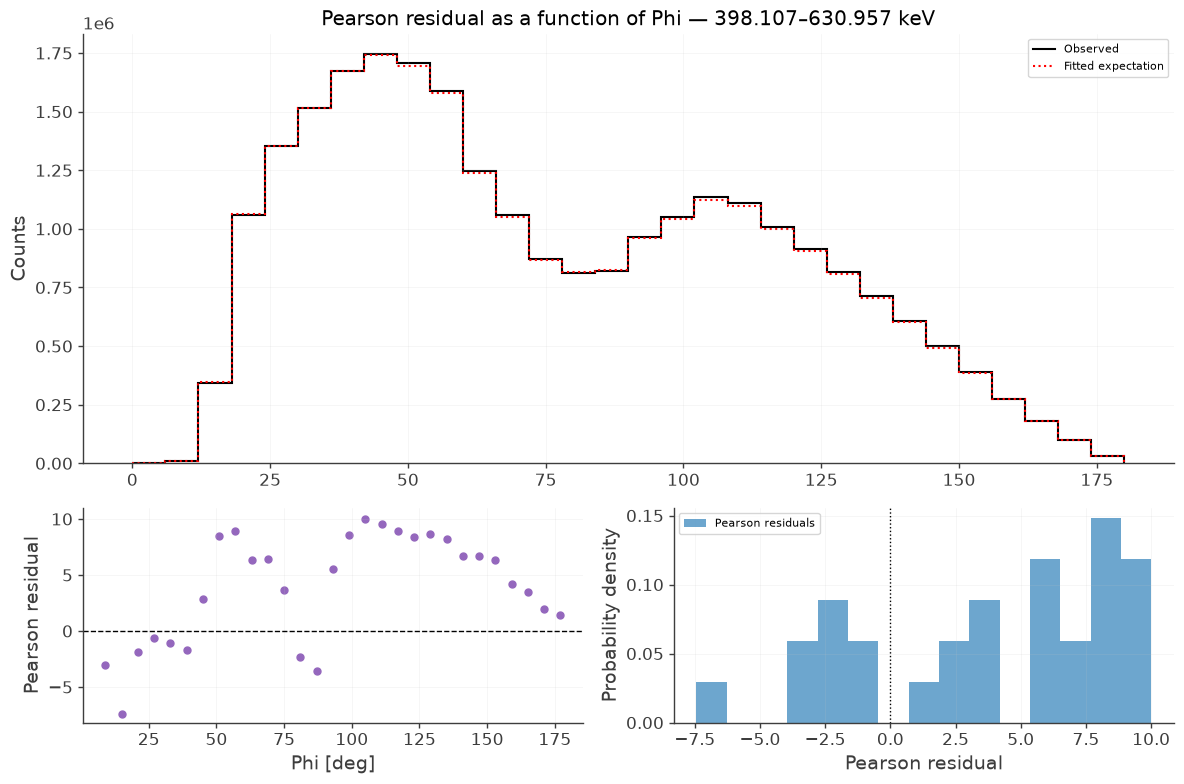

In [70]:
# Inspect counts and raw residuals versus Phi in the selected interval.
crab_selected_phi_figure = crab_selected_plotter.plot(
    "Phi_projection",
    residual_type="pearson",
    show_uncertainty=False,
    show_gaussian_reference=False
)
